Data length: 73964) arr length 1405316 and ratio 19.0
41 41 11 4
(4, 41, 41, 11, 19)
[[-0.9950548 -0.9950547 -0.9950548 ... -0.9950548 -0.9950548 -0.9950548]
 [-0.9950547 -0.9950548 -0.9950548 ... -0.9950548 -0.9950547 -0.9950547]
 [-0.9950548 -0.9950548 -0.9950548 ... -0.9950548 -0.9950548 -0.9950548]
 ...
 [-0.9950548 -0.9950548 -0.9950548 ... -0.9950548 -0.9950548 -0.9950548]
 [-0.9950548 -0.9950547 -0.9950548 ... -0.9950548 -0.9950548 -0.9950548]
 [-0.9950548 -0.9950547 -0.9950548 ... -0.9950548 -0.9950548 -0.9950548]]
[0, np.float32(-1680.8425)]
[1, np.float32(-1679.8866)]
[2, np.float32(-1672.9816)]
[3, np.float32(-1617.5806)]


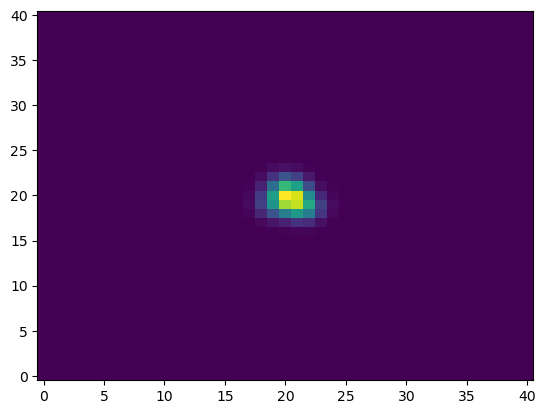

In [9]:
import numpy as np 
import awkward as ak
import uproot as up
import matplotlib.pyplot as plt

def load_event(file_name, tree_name, branch_name, ievent):
    with up.open(file_name) as file:
        tree = file[tree_name]
        branch = tree[branch_name]
        event_data = branch.array(library="ak", entry_start=ievent, entry_stop=ievent + 1)[0].to_numpy()
        nx = file['nx'].member('fVal')
        ny = file['ny'].member('fVal')
        neta = file['neta'].member('fVal')
        nFeatures = file['nFeatures'].member('fVal')
        dat_len = nx * ny * neta * nFeatures
        print(f'Data length: {dat_len}) arr length {len(event_data)} and ratio {float(len(event_data))/dat_len}')
        print(nx, ny, neta, nFeatures)
        nevents = len(event_data) // dat_len
        arr = event_data.reshape((nevents, nx, ny, neta, nFeatures))
        arr = np.moveaxis(arr, -1, 1)
        arr = np.moveaxis(arr, 0, -1)
    return arr

if __name__ == "__main__":
    # file_name = "/home/davidstewart/xscape-docker/X-SCAPE/build/dAu_seed5_5k_10cen.root"
    file_name = "/Users/du8478/FNO_Hydro_Data/flat/dAu_25ev_b_lt_2fm.root"
    tree_name = 't'
    branch_name = 'user_res'

    dat = load_event(file_name, tree_name, branch_name, ievent=4)
    print(dat.shape)
    plt.imshow(dat[0,:,:,2,1], aspect='auto', origin='lower')
    print(dat[3,:,:,2,1])
    for i in range(4):
        print([i,np.sum(dat[3,:,:,i,1])])
    # print(type(dat))